# Figures: Beerling et al. (2025) 1 Gt case vs. liming recommendations

Reads `point.zarr` for the 1 Gt E0 batch (scenario S1). Model CDR (export + SIC, or export only; set `CDR` in the first cell) is taken as the alkalinity flux over point-years from `start_year + 3`, area-weighted. ΔpH is `pH_diag` minus the initial soil pH (`pH0` on the 0–15 cm column).

In [15]:
import os, textwrap
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea

DATA = Path("../data")
ROOT = "s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension"
POSTPROC = os.environ.get("BEERLING_POSTPROC", f"{ROOT}/postproc/e0-conus-1gt")   # 1 Gt yr-1, E0
CDR = "export"                                    # Beerling CDR: "total" (export + SIC) or "export"
DPH_WINDOW = (0.5, 1.2)                          # recommendation ΔpH range for figs 1-2 (≈ the model's year-1 response)
SAVE_ON = True                                   # save each figure to FIGS as png
FIGS = Path("../figures/panels")
if SAVE_ON:
    FIGS.mkdir(parents=True, exist_ok=True)

CO2_PER_CCE = 2 * 44.01 / 100.09                 # t CO2-eq per t CCE
MMOLC_PER_T_CO2EQ = 1e9 / 44.01 / (0.15 * 1.30e3 * 1e4)   # 0-15 cm, BD 1.3
LB_ACRE = {"lb_acre": 1.0, "short_ton_acre": 2000.0, "lb_1000sqft": 43.56}

def wq(x, w, q):
    """Weighted quantile (midpoint CDF)."""
    x, w = np.asarray(x, float), np.asarray(w, float); m = np.isfinite(x) & np.isfinite(w)
    x, w = x[m], w[m]; o = np.argsort(x); x, w = x[o], w[o]
    return np.interp(q, (np.cumsum(w) - 0.5 * w) / w.sum(), x)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "savefig.dpi": 300, "savefig.bbox": "tight"})

In [16]:
# --- convert to co2-eq dose and compute buffering capacity rank by state
R = pd.read_csv(DATA / "recs_harmonized.csv", low_memory=False)
R = R[(R.flag.fillna("") == "") & (R.dpH_basis == "initial_pH")].copy()
R["dose_co2"] = R.dose_dpH_kgCCE_ha / 1000 * CO2_PER_CCE        # at each source's mixing depth
R["dose_ref"] = R.dose_dpH_mmolc_kg / MMOLC_PER_T_CO2EQ        # on the model's 0-15 cm, BD 1.3 soil mass
R["beta_rank"] = (R.dose_dpH_mmolc_kg / R.dpH).groupby(R.state).rank(pct=True)

# --- compute max dose per state and flag recommendations that exceed it
M = pd.read_csv(DATA / "max_dose.csv")
M["max_co2"] = (M.max_dose * M.dose_units.map(LB_ACRE) * 1.12085 * M.cce_factor.fillna(1.0)) / 1000 * CO2_PER_CCE
crop = ~M.dose_note.str.contains("turf|lawn|garden|acid-loving|fluid|application, potato|existing|sandy", case=False) \
       & (M.dose_units != "lb_1000sqft")
MAXC = M[crop].groupby("state").max_co2.max()                   # most permissive cropland limit per state
R["over_max"] = R.dose_co2 > R.state.str.replace("IN+MI", "IN", regex=False).map(MAXC)
W = R[R.dpH.between(*DPH_WINDOW)]

# --- read in beerling et al. data, compute co2-eq flux and D_pH
CDR_VAR = {"total": "cdr", "export": "cdr_export"}[CDR]          # as in fx-cdr/plot-cdr
FLUX_NAME = {"total": "annual alkalinity flux", "export": "annual exported alkalinity flux"}[CDR]
pt = xr.open_zarr(f"{POSTPROC}/point.zarr")[[CDR_VAR, "pH_diag", "pH0"]].load()
SPINUP = 3                                                       # first deployed years left out, as in fx-cdr/plot-cdr
AGE = pt.time - pt.start_year                                    # 0 = first year of application
c = pt[CDR_VAR].fillna(0.)                                       # cumulative t CO2/ha
FX = (c - c.shift(time=1, fill_value=0.)).where(AGE >= 0)        # annual alkalinity flux, t CO2-eq/ha/yr
ZCOL = np.arange(0, .15 + 1e-9, .005)                            # pH0 (7 layers) onto the 0-15 cm column, as in fx-ph/plot-ph
ph_init = xr.DataArray([np.interp(ZCOL, [0, .05, .15, .3, .6, 1., 2.], r).mean() for r in pt.pH0.values], dims="point")
DPH = pt.pH_diag - ph_init

fx = FX.where(AGE >= SPINUP)
yr1 = lambda da: da.where(AGE == 0).max("time")
B = pd.DataFrame(dict(area=pt.area_ha.values, flux=fx.mean("time").values, alk1=yr1(FX).values,
                      dpH1=yr1(DPH).values, dpH_mean=DPH.where(AGE >= SPINUP).mean("time").values))    # per cell
BY = fx.reset_coords(drop=True).to_dataframe("flux").dropna().join(pt.area_ha.to_series().rename("area"))  # per point-year
FLUX = wq(BY.flux, BY.area, [.1, .5, .9])                        # annual alkalinity flux, p10/p50/p90
print(f"{len(W)} recommendations with ΔpH {DPH_WINDOW}; {len(B):,} model cells, {len(BY):,} point-years")
print(f"flux p5/p50/p95 {wq(BY.flux, BY.area, [.05, .5, .95]).round(2)} t CO2/ha/yr (plot-cdr: {dict(total='7.54 / 9.21 / 11.13', export='4.36 / 7.33 / 10.53')[CDR]})")

1030 recommendations with ΔpH (0.5, 1.2); 2,322 model cells, 53,364 point-years
flux p5/p50/p95 [ 4.36  7.33 10.53] t CO2/ha/yr (plot-cdr: 4.36 / 7.33 / 10.53)


## 1a. Recommended doses vs. the model's annual alkalinity flux

Triangles are state maximum doses (ties stacked): each state's most permissive cropland limit, or with
`ALL_MAX_DOSES` every row of `max_dose.csv` (open = non-cropland: turf, gardens, fluid lime, ...).

In [17]:
# ———————————————————————————————————————————————
FS_LABEL = 20           # axis and colorbar labels
FS_TICK = 20            # tick labels, 1:1 label
FS_TEXT = 18            # legends and in-panel notes
C_REC = "0.6"          # recommended doses (bars)
C_EDGE = "0.2"         # outline of bars above the state max
C_MAX = "k"            # state max doses (triangles, open circles)
C_BEERLING = "C3"      # Beerling flux (line, ribbon, histogram)
S_MAX = 60              # state max dose marker size
CMAP = "viridis"       # ΔpH / dose colorbars
# ———————————————————————————————————————————————
plt.rcParams.update({"font.size": FS_LABEL, "axes.labelsize": FS_LABEL, "xtick.labelsize": FS_TICK,
                     "ytick.labelsize": FS_TICK, "legend.fontsize": FS_TEXT})
BEERLING_HANDLE = (Patch(color=C_BEERLING, alpha=.15, lw=0), Line2D([], [], color=C_BEERLING, lw=1.5))   # median + p10-p90 band

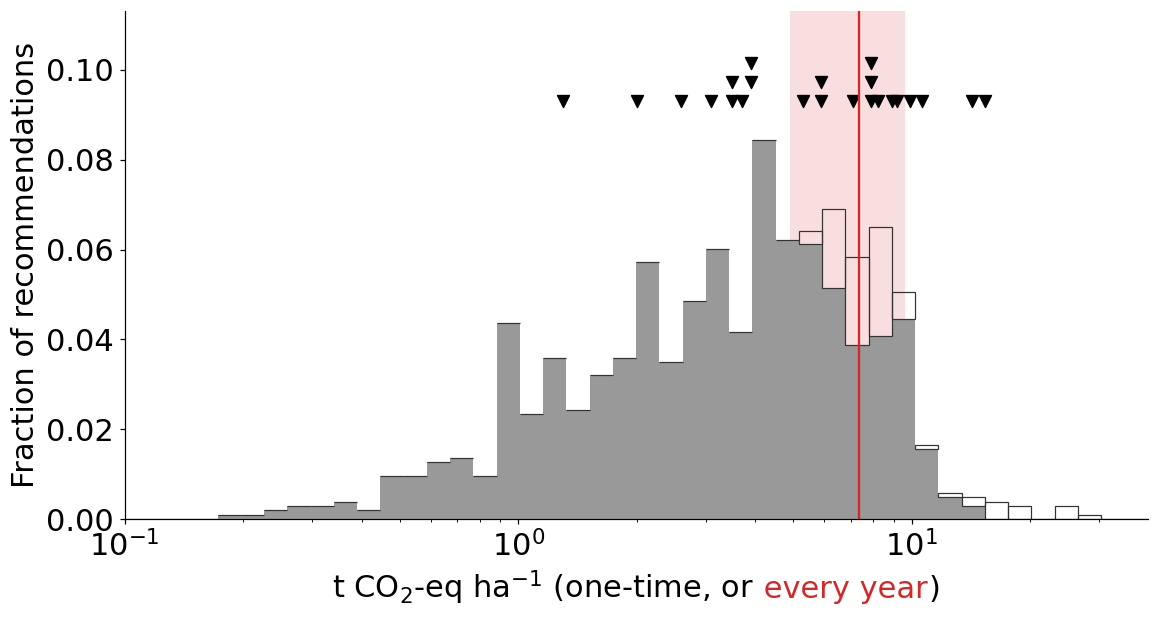

In [25]:
# ———————————————————————————————————————————————
BEERLING_HIST = False    # Beerling flux as a histogram (True) or median line + p10-p90 ribbon
ALL_MAX_DOSES = True    # every max dose in max_dose.csv (True) or each state's most permissive cropland limit
# ———————————————————————————————————————————————
ok, over = W.loc[~W.over_max, "dose_co2"], W.loc[W.over_max, "dose_co2"]
fig, ax = plt.subplots(figsize=(12, 6))
bins = np.logspace(-1, 1.6, 45)
_, _, (_, p_over) = ax.hist([ok, over], bins=bins, stacked=True, color=[C_REC, "none"],
                            weights=[np.full(len(x), 1 / len(W)) for x in (ok, over)],
                            label=[f"recommended dose, within state max (n={len(ok)})",
                                   f"recommended dose, above state max (n={len(over)})"])
for r in p_over:
    r.set_edgecolor(C_EDGE); r.set_linewidth(.8)
if BEERLING_HIST:
    ax.hist(BY.flux, bins=bins, weights=BY.area / BY.area.sum(), color=C_BEERLING, alpha=.45, zorder=0,
            label=f"Beerling 1 Gt {FLUX_NAME} (fraction of point-year area)")
else:
    ax.axvspan(FLUX[0], FLUX[2], color=C_BEERLING, alpha=.15, lw=0, zorder=0)
    ax.axvline(FLUX[1], color=C_BEERLING, lw=1.5, label=f"Beerling 1 Gt {FLUX_NAME} (median, p10–p90)")
top = ax.get_ylim()[1] * 1.05
D = M.assign(crop=crop) if ALL_MAX_DOSES else MAXC.to_frame().assign(crop=True)
D = D.assign(v=D.max_co2.round(1)).sort_values("v")
D["y"] = top * (1 + .045 * D.groupby("v").cumcount())
ax.scatter(D.v[D.crop], D.y[D.crop], marker="v", s=S_MAX, color=C_MAX,
           label="state max doses, cropland" if ALL_MAX_DOSES else "state max single dose")
# ax.scatter(D.v[~D.crop], D.y[~D.crop], marker="v", s=14, facecolor="none", edgecolor=C_MAX, lw=.6,
#            label="state max doses, non-cropland" if ALL_MAX_DOSES else None)
ax.set_ylim(0, D.y.max() * 1.07); ax.set_xscale("log") 
ax.set_xlim(bins[0], bins[-1])
XLAB = [("t CO$_2$-eq ha$^{-1}$ (one-time, or ", "k"), (" every year", C_BEERLING), (")", "k")]
ax.set_xlabel("".join(s for s, _ in XLAB), color="none")             # invisible: holds the label's space
ax.add_artist(AnnotationBbox(HPacker(children=[TextArea(s, textprops=dict(color=c, size=FS_LABEL)) for s, c in XLAB],
                                     align="baseline", pad=0, sep=0),
                             (.5, .5), xycoords=ax.xaxis.label, frameon=False, pad=0))   # colored label on top
ax.set_ylabel("Fraction per bin" if BEERLING_HIST else "Fraction of recommendations");
# ax.legend(frameon=False, fontsize=FS_TEXT, loc="upper left", bbox_to_anchor=(0, top / ax.get_ylim()[1]));   # below the triangles
# 
if SAVE_ON: fig.savefig(FIGS / "fig1a_dose_vs_flux.png")

In [19]:
print(f"median recommended dose, ΔpH {DPH_WINDOW[0]}–{DPH_WINDOW[1]} (n={len(W)}): {W.dose_co2.median():.2f} t CO2-eq/ha")

median recommended dose, ΔpH 0.5–1.2 (n=1030): 3.80 t CO2-eq/ha


## 1b. Recommended *fluxes* vs. the model's annual alkalinity flux

As in 1a, but we convert doses to time-mean fluxes by dividing by a recurrence interval (i.e., the dose happens only once every `recurrence-interval` years). By default, we use the recurrence interval from the 99th percentile of the Tsao et al. dataset ([Zenodo 15758275](https://doi.org/10.5281/zenodo.15758275)). 

We use this extreme upper bound because the Tsao et al. dataset reflects actual lime use, which likely falls below extension recommendations. I believe it also assumes all croplands are limed (by construction), which would decrease the frequency. Moreover, an upper-bound is conservative for the argument that Beerling et al. fluxes exceed recommendations. 

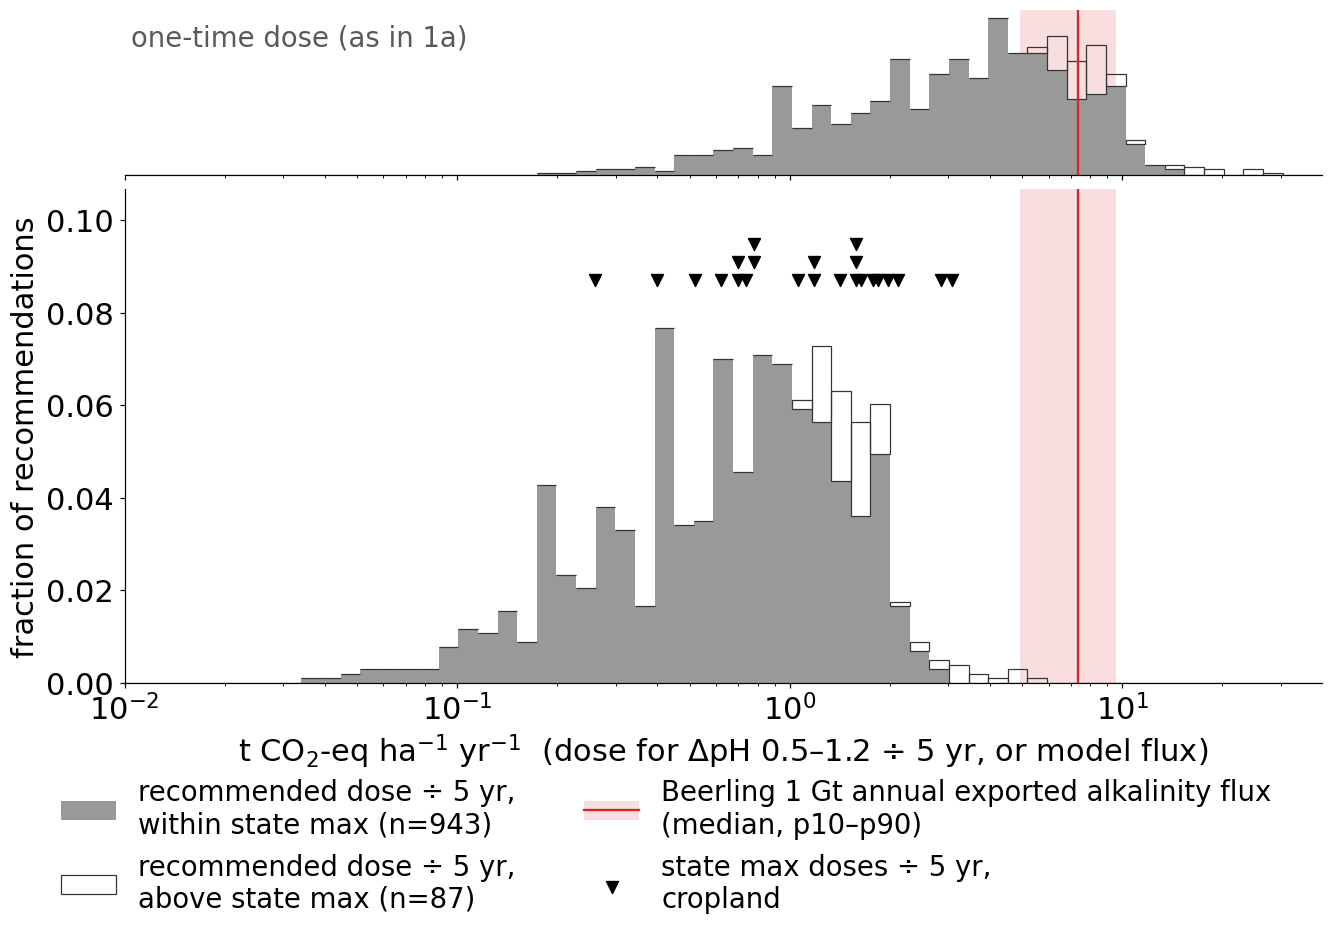

In [20]:
# ———————————————————————————————————————————————
RECURRENCE_YR = 5    # years between doses: P99 of the Tsao et al. lime frequency (05_lime_frequency, 1 / 0.204 yr-1)
# ———————————————————————————————————————————————
ok, over = W.loc[~W.over_max, "dose_co2"] / RECURRENCE_YR, W.loc[W.over_max, "dose_co2"] / RECURRENCE_YR
fig, (ax0, ax) = plt.subplots(2, 1, figsize=(12, 8.5), sharex=True, layout="constrained",
                              gridspec_kw=dict(height_ratios=[1, 3]))
bins = np.logspace(-2, 1.6, 62)                                  # same bin width as 1a, extended to lower fluxes
_, _, (_, p0) = ax0.hist([ok * RECURRENCE_YR, over * RECURRENCE_YR], bins=bins, stacked=True, color=[C_REC, "none"],
                         weights=[np.full(len(x), 1 / len(W)) for x in (ok, over)])    # top: 1a's one-time doses
_, _, (_, p_over) = ax.hist([ok, over], bins=bins, stacked=True, color=[C_REC, "none"],
                            weights=[np.full(len(x), 1 / len(W)) for x in (ok, over)],
                            label=[f"recommended dose ÷ {RECURRENCE_YR} yr,\nwithin state max (n={len(ok)})",
                                   f"recommended dose ÷ {RECURRENCE_YR} yr,\nabove state max (n={len(over)})"])
for r in [*p0, *p_over]:
    r.set_edgecolor(C_EDGE); r.set_linewidth(.8)
for a in (ax0, ax):
    if BEERLING_HIST:
        a.hist(BY.flux, bins=bins, weights=BY.area / BY.area.sum(), color=C_BEERLING, alpha=.45, zorder=0,
               label=f"Beerling 1 Gt {FLUX_NAME}\n(fraction of point-year area)" if a is ax else None)
    else:
        a.axvspan(FLUX[0], FLUX[2], color=C_BEERLING, alpha=.15, lw=0, zorder=0)
        a.axvline(FLUX[1], color=C_BEERLING, lw=1.5)
ax0.text(.005, .92, "one-time dose (as in 1a)", transform=ax0.transAxes, fontsize=FS_TEXT, va="top", color="0.35")
ax0.set_yticks([]); ax0.spines["left"].set_visible(False)
top = ax.get_ylim()[1] * 1.08                                    # triangles just above the tallest bar
D = M.assign(crop=crop) if ALL_MAX_DOSES else MAXC.to_frame().assign(crop=True)
D = D.assign(v=D.max_co2.round(1) / RECURRENCE_YR).sort_values("v")
D["y"] = top * (1 + .045 * D.groupby("v").cumcount())
ax.scatter(D.v[D.crop], D.y[D.crop], marker="v", s=S_MAX, color=C_MAX,
           label=f"state max doses ÷ {RECURRENCE_YR} yr,\ncropland" if ALL_MAX_DOSES else f"state max single dose\n÷ {RECURRENCE_YR} yr")
ax.set_ylim(0, D.y.max() * 1.08); ax.set_xscale("log"); ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel(f"t CO$_2$-eq ha$^{{-1}}$ yr$^{{-1}}$  (dose for ΔpH {DPH_WINDOW[0]}–{DPH_WINDOW[1]} ÷ {RECURRENCE_YR} yr, or model flux)")
ax.set_ylabel("fraction per bin" if BEERLING_HIST else "fraction of recommendations")
h, l = ax.get_legend_handles_labels()
if not BEERLING_HIST:
    h.insert(2, BEERLING_HANDLE); l.insert(2, f"Beerling 1 Gt {FLUX_NAME}\n(median, p10–p90)")
fig.legend(h, l, loc="outside lower center", ncols=2, frameon=False, columnspacing=2.5);
# 
if SAVE_ON: fig.savefig(FIGS / "fig1b_flux_vs_flux.png")

## 2. Which soils get doses that large?

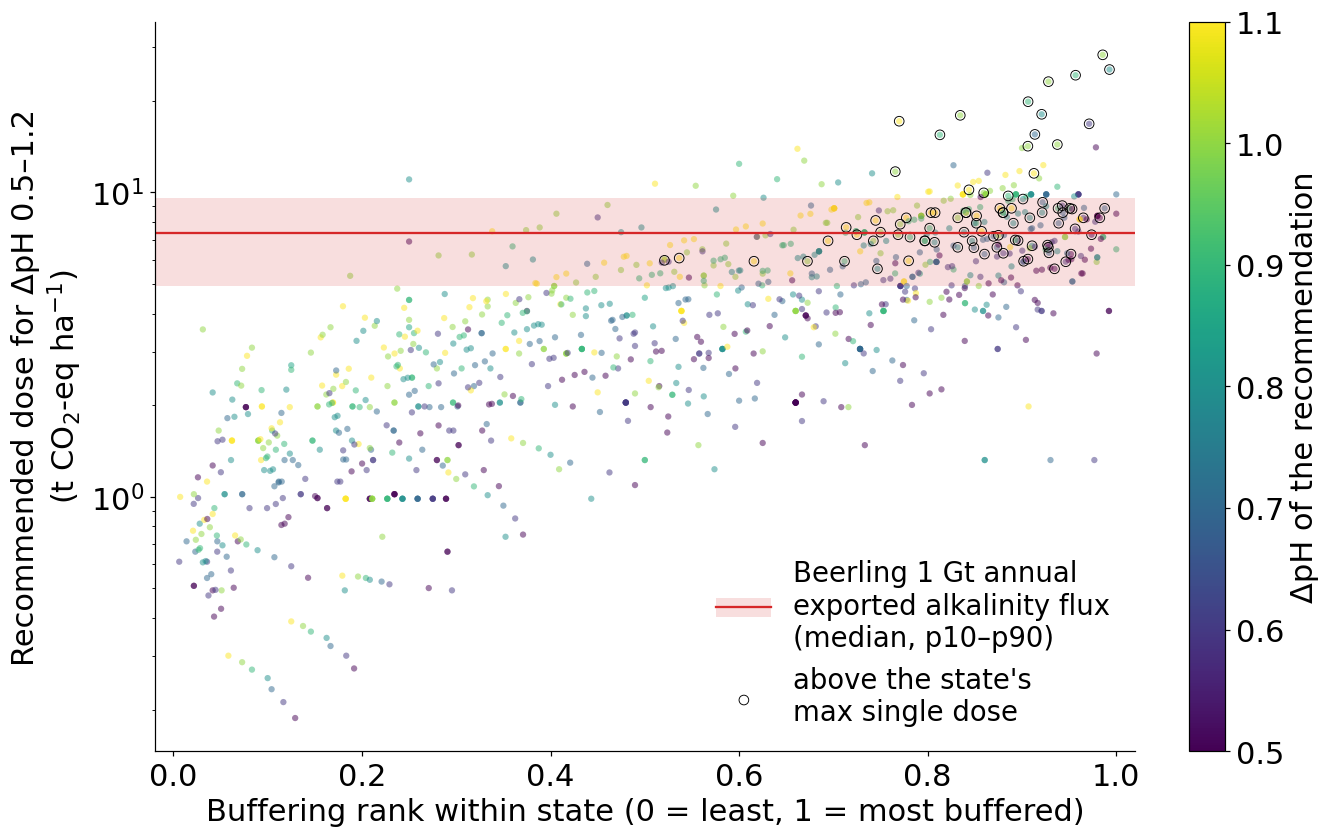

In [22]:
fig, ax = plt.subplots(figsize=(12, 7.5), layout="constrained")
sc = ax.scatter(W.beta_rank, W.dose_co2, c=W.dpH, s=17, alpha=.5, cmap=CMAP, lw=0)
ax.axhspan(FLUX[0], FLUX[2], color=C_BEERLING, alpha=.15, lw=0)
ax.axhline(FLUX[1], color=C_BEERLING, lw=1.5)
over_h = ax.scatter(W[W.over_max].beta_rank, W[W.over_max].dose_co2, s=40, facecolor="none", edgecolor=C_MAX, lw=.6)
ax.set_yscale("log"); ax.set_xlim(-.02, 1.02)
ax.set_xlabel("Buffering rank within state (0 = least, 1 = most buffered)")
ax.set_ylabel(f"Recommended dose for ΔpH {DPH_WINDOW[0]}–{DPH_WINDOW[1]}\n(t CO$_2$-eq ha$^{{-1}}$)")
ax.legend([BEERLING_HANDLE, over_h], [textwrap.fill(f"Beerling 1 Gt {FLUX_NAME} (median, p10–p90)", 24), "above the state's\nmax single dose"],
          loc="lower right", frameon=False)
cb = fig.colorbar(sc, ax=ax, label="ΔpH of the recommendation"); cb.solids.set_alpha(1)
# 
if SAVE_ON: fig.savefig(FIGS / "fig2_dose_vs_buffering.png")

## 3. pH response to the same alkalinity

Liming rows and model cells are binned by t CO₂-eq ha⁻¹ across the model's p10–p90 annual flux (model cells: their mean
annual flux; liming: single dose, on the model's 0–15 cm soil mass). Points are bin medians, bars the interquartile range.

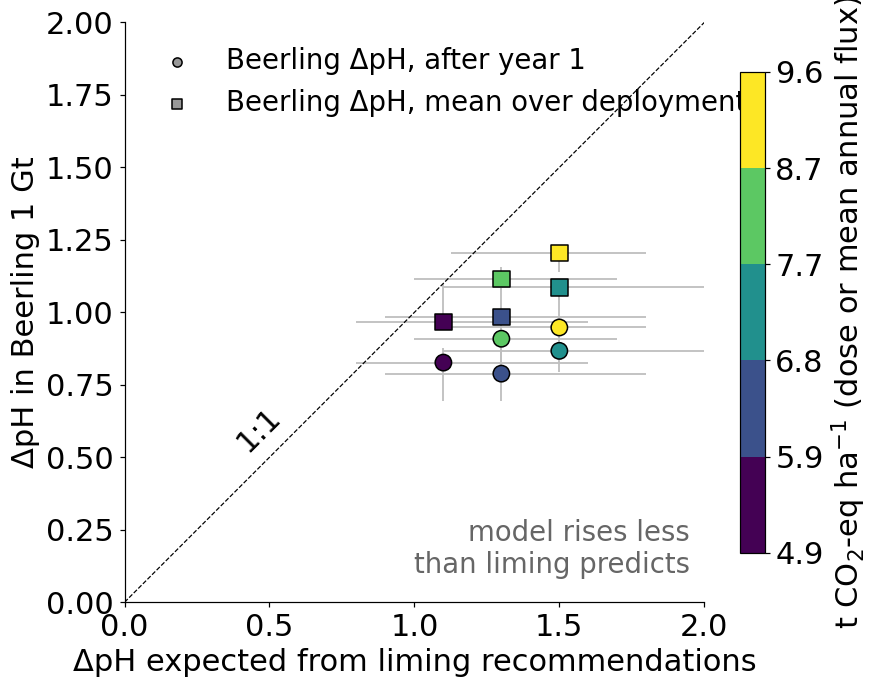

In [14]:
edges = np.linspace(FLUX[0], FLUX[2], 6)

def binned(dose, y, w=None):
    """p25/p50/p75 of y within each dose bin."""
    b = pd.cut(dose, edges, labels=False).values
    w = np.ones(len(y)) if w is None else np.asarray(w)
    return np.array([wq(y.values[b == i], w[b == i], [.25, .5, .75]) for i in range(len(edges) - 1)]).T

lx = binned(R.dose_ref, R.dpH)
fig, ax = plt.subplots(figsize=(9, 7.5), layout="constrained")
for col, mk, lab in (("dpH1", "o", "after year 1"), ("dpH_mean", "s", "mean over deployment")):
    by = binned(B.flux, B[col], B.area)
    ax.errorbar(lx[1], by[1], xerr=abs(lx[[0, 2]] - lx[1]), yerr=abs(by[[0, 2]] - by[1]), fmt="none", ecolor="0.75", lw=1.2)
    sc = ax.scatter(lx[1], by[1], c=(edges[:-1] + edges[1:]) / 2, cmap=CMAP, norm=BoundaryNorm(edges, 256),
                    marker=mk, s=115, edgecolor="k", lw=1, zorder=3)
    ax.scatter([], [], marker=mk, s=115, color="0.6", edgecolor="k", lw=1, label=lab)
ax.plot([0, 2], [0, 2], "k--", lw=.8)
ax.text(1.72, 1.8, "1:1", rotation=45, rotation_mode="anchor", ha="center", va="bottom", fontsize=FS_TICK)
ax.text(1.95, .1, "model rises less\nthan liming predicts", ha="right", fontsize=FS_TEXT, color="0.4")
ax.set(xlim=(0, 2), ylim=(0, 2), aspect="equal", xlabel="ΔpH expected from liming recommendations",
       ylabel="ΔpH in Beerling 1 Gt")
ax.legend(frameon=False, loc="upper left", title="Beerling ΔpH", alignment="left")
fig.colorbar(sc, ax=ax, ticks=edges, format="%.1f", shrink=.85,
             label="dose or mean annual flux\n(t CO$_2$-eq ha$^{-1}$)");
# 
# if SAVE_ON: fig.savefig(FIGS / "fig3_dpH_response.png")

In [ ]:
# ---